In [ ]:
pip install matplotlib scipy numpy

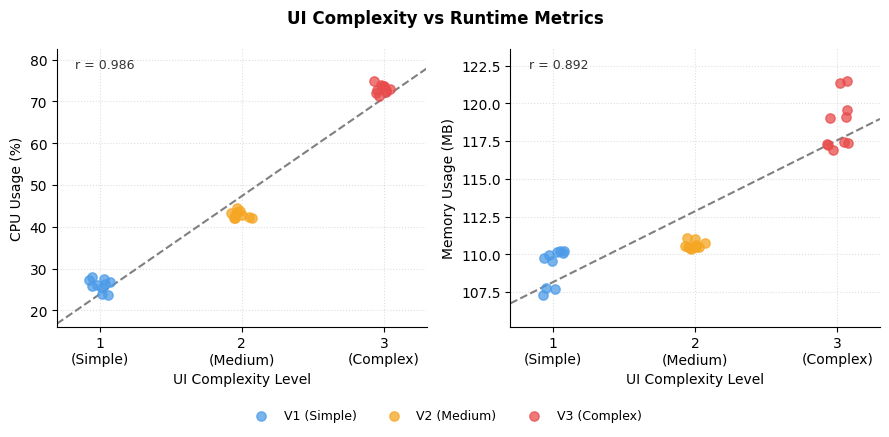

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

# Data raw (30 observations)
variant = np.array([1]*10 + [2]*10 + [3]*10)

cpu = np.array([26.08,26.76,26.22,25.41,28.02,25.73,27.27,23.75,23.91,27.49,
                43.28,42.04,42.29,42.12,42.19,42.83,43.45,42.85,43.85,44.53,
                72.81,72.11,71.32,73.93,73.60,72.97,72.73,73.75,72.25,74.84])

memory = np.array([107.73,107.80,107.32,110.11,110.19,110.23,109.96,109.75,110.13,109.54,
                   111.11,111.04,110.56,110.72,110.42,110.48,110.34,110.46,110.62,110.50,
                   117.37,117.44,121.46,119.08,121.33,119.53,117.21,119.06,117.31,116.94])

colors = ['#4C9BE8', '#F5A623', '#E84C4C']
labels = {1: 'V1 (Simple)', 2: 'V2 (Medium)', 3: 'V3 (Complex)'}

np.random.seed(42)  # supaya jitter konsisten setiap kali di-run

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

datasets = [
    (cpu,    'CPU Usage (%)',     'r = 0.986'),
    (memory, 'Memory Usage (MB)', 'r = 0.892'),
]

for ax, (y_data, ylabel, stats_label) in zip(axes, datasets):
    for v in [1, 2, 3]:
        idx = variant == v
        jitter = np.random.uniform(-0.08, 0.08, idx.sum())
        ax.scatter(variant[idx] + jitter, y_data[idx],
                   color=colors[v-1], label=labels[v],
                   alpha=0.75, s=45, zorder=3)

    # Regression line
    slope, intercept, *_ = stats.linregress(variant, y_data)
    x_line = np.linspace(0.7, 3.3, 100)
    ax.plot(x_line, slope * x_line + intercept,
            color='gray', linewidth=1.5, linestyle='--', zorder=2)

    # Y-axis range: tight around data
    padding = (y_data.max() - y_data.min()) * 0.15
    ax.set_ylim(y_data.min() - padding, y_data.max() + padding)

    ax.set_xlabel('UI Complexity Level', fontsize=10)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_xlim(0.7, 3.3)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['1\n(Simple)', '2\n(Medium)', '3\n(Complex)'])
    ax.annotate(stats_label, xy=(0.05, 0.93), xycoords='axes fraction',
                fontsize=9, color='#333333')
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Shared legend
handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.08), fontsize=9, frameon=False)

fig.suptitle('UI Complexity vs Runtime Metrics', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('scatter_plots.pdf', bbox_inches='tight', dpi=300)
plt.savefig('scatter_plots.png', bbox_inches='tight', dpi=300)
plt.show()